Video Loaded: Resolution 1280x720 | FPS: 30.00 | Delta_t: 0.0333s
Geometry Initialized: Center (np.uint16(684), np.uint16(280)), Radius 154
Detected 193 initial features within the safe tracking band.
Initialization complete. Found 193 features for KLT tracking.


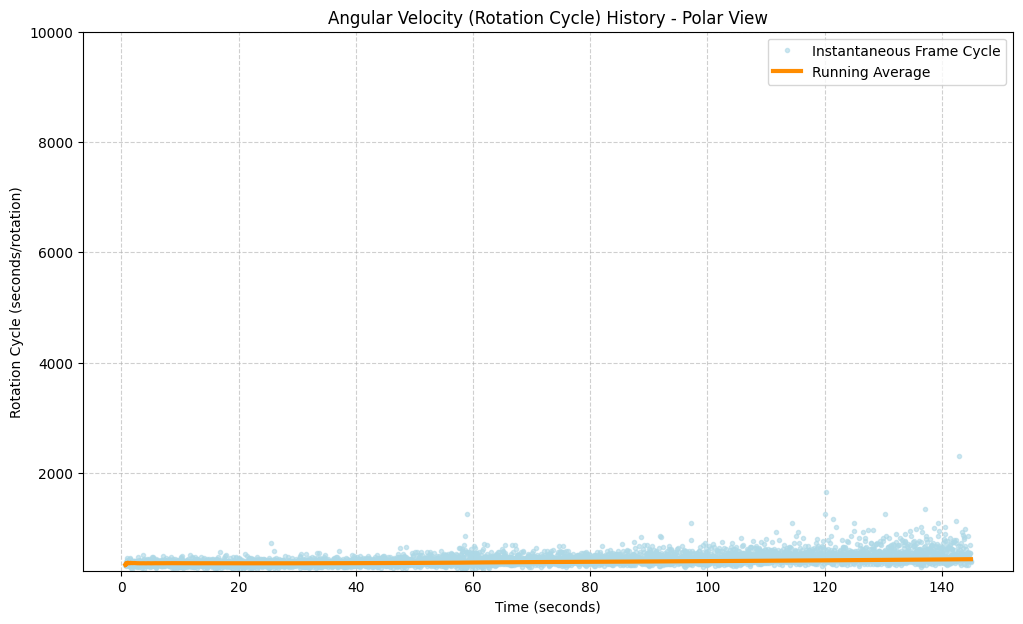

In [1]:
""" Instant Rotation Cycle Estimation from the bottom (polar) view"""
import cv2
import numpy as np
import time
import math
import matplotlib.pyplot as plt

VIDEO_PATH = "../globe_image/ground_floor_rotation_video_bottom.avi" 
START_FRAME_INDEX = 20 

# KLT feature detection parameters
MAX_FEATURES = 250
FEATURE_QUALITY_LEVEL = 0.001
FEATURE_MIN_DISTANCE = 10
RE_TRACK_MIN_COUNT = 40 

# KLT Optical Flow Parameters
LK_WINDOW_SIZE = (21, 21) 
LK_MAX_LEVEL = 3
LK_CRITERIA = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03)

# circular band parameters (ROI)
MIN_TRACKING_BAND_RATIO = 0.40 
MAX_TRACKING_BAND_RATIO = 0.85 

# Hough Circle parameters
HOUGH_DP = 1 
HOUGH_MIN_DIST = 100 
HOUGH_PARAM1 = 50 
HOUGH_PARAM2 = 30 

# results variables
time_history = []
velocity_history = []
average_history = []

# general info
globe_center = None
globe_radius = None
fps = 0
frame_counter = 0

prev_points = None 
prev_gray = None 
EXPECTED_CYCLE = 414.0 

def find_globe_geometry(frame):
    """
    Finds the center and radius of the globe.
    """
    if frame is None:
        return None, None
        
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (9, 9), 2)
    
    min_rad = int(frame.shape[0]*0.15)
    max_rad = int(frame.shape[0]*0.4)
    
    circles = cv2.HoughCircles(blurred, cv2.HOUGH_GRADIENT, HOUGH_DP, HOUGH_MIN_DIST,
                               param1=HOUGH_PARAM1, param2=HOUGH_PARAM2, 
                               minRadius=min_rad, maxRadius=max_rad)

    if circles is not None:
        circles = np.uint16(np.around(circles))
        best_circle = circles[0, 0]
        center = (best_circle[0], best_circle[1])
        radius = best_circle[2]
        
        print(f"Geometry Initialized: Center {center}, Radius {radius}")
        return center, radius
    else:
        print("Hough Circle failed to detect the globe.")
        return None, None

def detect_initial_features_in_band(frame_gray, center, radius):
    """
    Detects strong corners and restricts them to the central band using a mask.
    """
    mask = np.zeros_like(frame_gray)
    inner_radius = int(radius * MIN_TRACKING_BAND_RATIO)
    outer_radius = int(radius * MAX_TRACKING_BAND_RATIO)
    
    # Create the circular mask
    cv2.circle(mask, center, outer_radius, 255, -1) 
    cv2.circle(mask, center, inner_radius, 0, -1) 
    
    points = cv2.goodFeaturesToTrack(frame_gray, 
                                     maxCorners=MAX_FEATURES, 
                                     qualityLevel=FEATURE_QUALITY_LEVEL, 
                                     minDistance=FEATURE_MIN_DISTANCE,
                                     mask=mask)

    if points is None or len(points) < RE_TRACK_MIN_COUNT:
        return None
        
    print(f"Detected {len(points)} initial features within the safe tracking band.")
    return points

def calculate_angular_velocity(p0, p1, center, delta_t):
    """
    Calculates the instantaneous angular velocity based on the displacement of tracked features
    using the change in polar angle relative to the center.
    """
    if not p0.size or not p1.size or len(p0) != len(p1):
        return None

    cx, cy = center
    angular_displacements = []

    p0_reshaped = p0.reshape(-1, 2)
    p1_reshaped = p1.reshape(-1, 2)

    for i in range(len(p0_reshaped)):
        x0, y0 = p0_reshaped[i]
        angle0 = math.atan2(y0 - cy, x0 - cx)
        
        x1, y1 = p1_reshaped[i]
        angle1 = math.atan2(y1 - cy, x1 - cx)
        
        delta_angle = angle1 - angle0
        
        if delta_angle > math.pi:
            delta_angle -= 2 * math.pi
        elif delta_angle < -math.pi:
            delta_angle += 2 * math.pi
            
        if abs(delta_angle) > 1e-6: 
            angular_displacements.append(delta_angle)

    if not angular_displacements:
        return None

    # Use the median angular displacement 
    median_delta_angle = np.median(angular_displacements)
    
    omega = median_delta_angle / delta_t
    
    if abs(omega) < 1e-9:
        return None
        
    rotation_cycle = abs(2 * math.pi / omega)
    
    return rotation_cycle


def apply_geometric_filter(p_old, p_new, center, radius):
    """
    Filters tracked points (p_new) to ensure they remain within the circular tracking band.
    """
    cx, cy = center
    
    min_dist_sq = (radius * MIN_TRACKING_BAND_RATIO)**2
    max_dist_sq = (radius * MAX_TRACKING_BAND_RATIO)**2

    p_new_flat = p_new.reshape(-1, 2)
    
    # Calculate squared distances from the center
    distances_sq = (p_new_flat[:, 0] - cx)**2 + (p_new_flat[:, 1] - cy)**2
    is_in_band = (distances_sq >= min_dist_sq) & (distances_sq <= max_dist_sq)
    
    # Apply the mask to both the old and new point sets
    filtered_p_new = p_new[is_in_band]
    filtered_p_old = p_old[is_in_band]
    
    return filtered_p_old, filtered_p_new


def plot_results_after_processing():
    """
    Show the angular velocity estimates over time
    """
    global time_history, velocity_history, average_history, EXPECTED_CYCLE

    plt.figure(figsize=(12, 7))
    plt.title("Angular Velocity (Rotation Cycle) History - Polar View")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Rotation Cycle (seconds/rotation)")
    
    plt.plot(time_history, velocity_history, 'o', label='Instantaneous Frame Cycle', markersize=3, 
             color='lightblue', alpha=0.6)
    plt.plot(time_history, average_history, '-', label='Running Average', linewidth=3, 
             color='darkorange')

    data_min = min(velocity_history) * 0.95
    plt.ylim(data_min, 10000)
    data_min = min(velocity_history) * 0.95
    data_max = max(velocity_history) * 1.05
    
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.show(block=True) 


def process_live_video():
    """
    The main loop for KLT tracking, velocity estimation, and video visualization.
    """
    global globe_center, globe_radius, fps, frame_counter, prev_points, prev_gray
    global time_history, velocity_history, average_history

    cap = cv2.VideoCapture(VIDEO_PATH)

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)) 

    delta_t = 1.0 / fps
    print(f"Video Loaded: Resolution {frame_width}x{frame_height} | FPS: {fps:.2f} | Delta_t: {delta_t:.4f}s")
    
    # go to intial reference frame
    while frame_counter < START_FRAME_INDEX:
        ret, frame = cap.read()
        if not ret: break
        frame_counter += 1

    globe_center, globe_radius = find_globe_geometry(frame)
    if globe_center is None: 
        cap.release()
        return
    
    prev_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    prev_points = detect_initial_features_in_band(prev_gray, globe_center, globe_radius)
    
    print(f"Initialization complete. Found {len(prev_points)} features for KLT tracking.")
    
    rotation_cycle_smoothed = None
    
    # Real time tracking loop
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
            
        frame_counter += 1
        start_time = time.time()
        current_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        
        # optical flow tracking
        current_points, status, err = cv2.calcOpticalFlowPyrLK(
            prev_gray, 
            current_gray, 
            prev_points, 
            None, 
            winSize=LK_WINDOW_SIZE, 
            maxLevel=LK_MAX_LEVEL, 
            criteria=LK_CRITERIA
        )
        
        # filter good points
        good_old = prev_points[status == 1]
        good_new = current_points[status == 1]
        
        if good_new.size > 0:
            good_old, good_new = apply_geometric_filter(good_old, good_new, globe_center, globe_radius)
        
        final_inlier_count = len(good_new)
        
        # check if we have to re initialize feature detection
        re_detect_needed = (final_inlier_count < RE_TRACK_MIN_COUNT)

        if re_detect_needed:
            new_points = detect_initial_features_in_band(current_gray, globe_center, globe_radius)
            
            if new_points is not None and len(new_points) >= RE_TRACK_MIN_COUNT:
                prev_points = new_points
            else:
                prev_points = good_new.reshape(-1, 1, 2) if good_new.size > 0 else np.array([])
        else:
             prev_points = good_new.reshape(-1, 1, 2)
        
        prev_gray = current_gray.copy() 
        
        # angular velocity calculation
        current_time_sec = frame_counter * delta_t
        cycle_estimate = None

        if good_old.size > 0 and good_new.size > 0 and len(good_new) >= 5: 
            cycle_estimate = calculate_angular_velocity(good_old, good_new, globe_center, delta_t)
            
            if cycle_estimate is not None:
                # save results
                time_history.append(current_time_sec)
                velocity_history.append(cycle_estimate)
                current_avg = sum(velocity_history) / len(velocity_history)
                average_history.append(current_avg)
                
                if rotation_cycle_smoothed is None:
                    rotation_cycle_smoothed = cycle_estimate
                else:
                    rotation_cycle_smoothed = 0.9 * rotation_cycle_smoothed + 0.1 * cycle_estimate 
            
        # visualization
        processing_time = time.time() - start_time
        
        cycle_display = "N/A"
        if rotation_cycle_smoothed is not None:
            cycle_display = f"Smoothed Cycle: {rotation_cycle_smoothed:.2f} s/rot"
            
            if average_history:
                 avg_cycle_display = f"Avg Cycle: {average_history[-1]:.2f} s/rot"
                 cv2.putText(frame, avg_cycle_display, (frame_width - 320, 60), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 100, 0), 2)
                 
            cv2.putText(frame, cycle_display, (frame_width - 320, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
                
        cv2.putText(frame, f"Time: {current_time_sec:.2f}s", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 0), 2)
        cv2.putText(frame, f"Active Tracks: {final_inlier_count}", (10, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 100, 255), 2)

        speed_check = f"Proc Time: {processing_time*1000:.2f} ms | FPS Target: {delta_t*1000:.2f} ms"
        cv2.putText(frame, speed_check, (10, frame_height - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 255), 1)

        # Draw the active features
        for point in good_new:
            x, y = point.ravel().astype(int)
            frame = cv2.circle(frame, (x, y), 3, (0, 255, 255), -1)

        # Draw the tracking band boundaries
        cv2.circle(frame, globe_center, int(globe_radius * MIN_TRACKING_BAND_RATIO), (0, 165, 255), 1)
        cv2.circle(frame, globe_center, int(globe_radius * MAX_TRACKING_BAND_RATIO), (0, 165, 255), 1)

        cv2.imshow('KLT Optical Flow Tracker (Polar View)', frame)
        
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()
    
    plot_results_after_processing()


if __name__ == "__main__":
    plt.ioff()
    process_live_video()